In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FINAL_DIR = PROJECT_ROOT / "data" / "final"
TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

for folder in [TABLES_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [2]:
df = pd.read_csv(
    FINAL_DIR / "model_features_20d_provisional.csv",
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

TARGET = "RV_Future_20D"

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

assert len(df) == 3944
assert df[MARKET_FEATURES + [TARGET]].notna().all().all()

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00


In [3]:
HORIZON = 20
SEQUENCE_LENGTH = 20

development_start = pd.Timestamp("2018-01-01")
validation_start = pd.Timestamp("2020-01-01")

development_start_idx = df.index[
    df["Date"] >= development_start
][0]

validation_start_idx = df.index[
    df["Date"] >= validation_start
][0]

# Purge targets that would extend into the next period.
fit_end_idx = development_start_idx - HORIZON - 1
development_end_idx = validation_start_idx - HORIZON - 1

fit_indices = np.arange(
    SEQUENCE_LENGTH - 1,
    fit_end_idx + 1
)

development_indices = np.arange(
    development_start_idx,
    development_end_idx + 1
)

validation_indices = df.index[
    (df["Date"] >= "2020-01-01") &
    (df["Date"] < "2023-01-01")
].to_numpy()

print("Fit observations:", len(fit_indices))
print("Development observations:", len(development_indices))
print("Validation observations:", len(validation_indices))

assert len(validation_indices) == 756

assert fit_indices.max() + HORIZON < development_indices.min()
assert development_indices.max() + HORIZON < validation_indices.min()

print("Chronological split checks passed!")

Fit observations: 1914
Development observations: 483
Validation observations: 756
Chronological split checks passed!


In [4]:
scaler = StandardScaler()

# Fit on rows whose features are available in the fitting period.
scaler.fit(
    df.loc[:fit_end_idx, MARKET_FEATURES]
)

scaled_features = scaler.transform(
    df[MARKET_FEATURES]
)

print("Scaled feature matrix:", scaled_features.shape)

Scaled feature matrix: (3944, 7)


In [5]:
def create_sequences(features, targets, indices, sequence_length):
    X = []
    y = []

    for idx in indices:
        start = idx - sequence_length + 1

        sequence = features[start:idx + 1]

        X.append(sequence)
        y.append(targets[idx])

    return np.asarray(X), np.asarray(y)


targets = df[TARGET].to_numpy()

X_fit, y_fit = create_sequences(
    scaled_features,
    targets,
    fit_indices,
    SEQUENCE_LENGTH
)

X_dev, y_dev = create_sequences(
    scaled_features,
    targets,
    development_indices,
    SEQUENCE_LENGTH
)

X_val, y_val = create_sequences(
    scaled_features,
    targets,
    validation_indices,
    SEQUENCE_LENGTH
)

print("Fit:", X_fit.shape, y_fit.shape)
print("Development:", X_dev.shape, y_dev.shape)
print("Validation:", X_val.shape, y_val.shape)

assert X_fit.shape[1:] == (
    SEQUENCE_LENGTH,
    len(MARKET_FEATURES)
)

assert len(X_val) == 756

print("LSTM sequences created successfully!")

Fit: (1914, 20, 7) (1914,)
Development: (483, 20, 7) (483,)
Validation: (756, 20, 7) (756,)
LSTM sequences created successfully!


In [6]:
model = Sequential([
    Input(shape=(
        SEQUENCE_LENGTH,
        len(MARKET_FEATURES)
    )),

    LSTM(32),

    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1, activation="softplus")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,665 (22.13 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_fit,
    y_fit,

    validation_data=(X_dev, y_dev),

    epochs=50,
    batch_size=32,

    callbacks=[early_stopping],

    shuffle=False,
    verbose=1
)

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.2909 - mae: 0.5178 - val_loss: 0.1063 - val_mae: 0.3087
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0431 - mae: 0.1692 - val_loss: 0.0028 - val_mae: 0.0461
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0020 - mae: 0.0330 - val_loss: 5.0703e-04 - val_mae: 0.0193
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.9371e-04 - mae: 0.0195 - val_loss: 3.3090e-04 - val_mae: 0.0151
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9179e-04 - mae: 0.0169 - val_loss: 3.1038e-04 - val_mae: 0.0138
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.1506e-04 - mae: 0.0163 - val_loss: 3.1775e-04 - val_mae: 0.0136
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.3615e-04 - mae: 0.0163 - val_loss: 3.3005e-04 - val_mae: 0.0135
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.9964e-04 - mae: 0.0159 - val_loss: 3.3843e-04 - val_mae: 0.0135
Epoch 9/50
60/60 ━━━━━━━━━━

In [8]:
lstm_predictions = model.predict(
    X_val,
    verbose=0
).flatten()

assert len(lstm_predictions) == len(y_val)
assert np.isfinite(lstm_predictions).all()
assert (lstm_predictions >= 0).all()

print("LSTM validation predictions:", len(lstm_predictions))
print("First five predictions:", lstm_predictions[:5])

LSTM validation predictions: 756
First five predictions: [0.02951954 0.02993614 0.02952712 0.02941865 0.02937556]


In [9]:
def evaluate_forecast(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(y_true, y_pred)

    epsilon = 1e-4

    safe_mape = np.mean(
        np.abs(y_true - y_pred) /
        np.maximum(np.abs(y_true), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }


lstm_metrics = evaluate_forecast(
    y_val,
    lstm_predictions
)

print("=" * 60)
print("LSTM VALIDATION RESULTS")
print("=" * 60)

for metric, value in lstm_metrics.items():
    print(f"{metric}: {value:.6f}")

LSTM VALIDATION RESULTS
RMSE: 0.049478
MAE: 0.023611
Safe_MAPE: 32.598020


In [10]:
comparison = pd.DataFrame([
    {
        "Model": "GARCH(1,1)",
        "RMSE": 0.034771,
        "MAE": 0.019197,
        "Safe_MAPE": 29.495222
    },
    {
        "Model": "Linear Regression",
        "RMSE": 0.035895,
        "MAE": 0.018616,
        "Safe_MAPE": 27.730350
    },
    {
        "Model": "XGBoost",
        "RMSE": 0.037992,
        "MAE": 0.019562,
        "Safe_MAPE": 27.495317
    },
    {
        "Model": "Random Forest",
        "RMSE": 0.038677,
        "MAE": 0.019927,
        "Safe_MAPE": 27.855195
    },
    {
        "Model": "Persistence",
        "RMSE": 0.043013,
        "MAE": 0.023945,
        "Safe_MAPE": 37.751981
    },
    {
        "Model": "LSTM",
        **lstm_metrics
    }
])

comparison = comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

display(comparison.round(6))

comparison.to_csv(
    TABLES_DIR / "all_models_validation_comparison.csv",
    index=False
)

,Model,RMSE,MAE,Safe_MAPE
0,"GARCH(1,1)",0.034771,0.019197,29.495222
1,Linear Regression,0.035895,0.018616,27.730350
2,XGBoost,0.037992,0.019562,27.495317
3,Random Forest,0.038677,0.019927,27.855195
4,Persistence,0.043013,0.023945,37.751981
5,LSTM,0.049478,0.023611,32.598020


In [11]:
lstm_validation = pd.DataFrame({
    "Date": df.loc[validation_indices, "Date"].to_numpy(),
    "Actual": y_val,
    "Predicted": lstm_predictions
})

lstm_validation.to_csv(
    TABLES_DIR / "lstm_validation_predictions.csv",
    index=False
)

print("LSTM validation predictions saved successfully!")

LSTM validation predictions saved successfully!


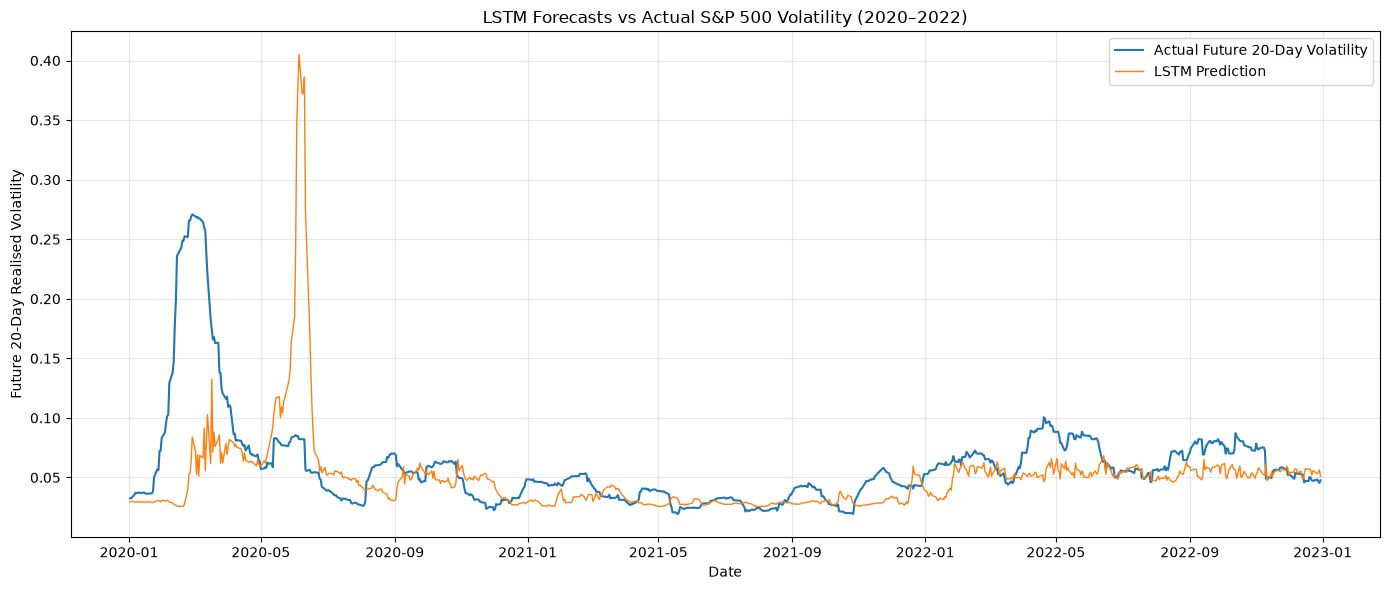

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    lstm_validation["Date"],
    lstm_validation["Actual"],
    label="Actual Future 20-Day Volatility",
    linewidth=1.5
)

plt.plot(
    lstm_validation["Date"],
    lstm_validation["Predicted"],
    label="LSTM Prediction",
    linewidth=1
)

plt.title(
    "LSTM Forecasts vs Actual S&P 500 Volatility (2020–2022)"
)

plt.xlabel("Date")
plt.ylabel("Future 20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "lstm_validation_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()